# Final Model Evaluation

In this notebook, we will evaluate the locked modeling system on the untouched 2025 season. The analysis keeps three questions separate:

1. How do the individual statistics-only models and the ensemble perform?
2. How does the selected statistics-only system compare to the betting market?
3. Does a separately trained statistics-plus-market hybrid improve either prediction?

In [1]:
from pathlib import Path
import sys

# Allow the notebook to run from either the project root or the notebooks folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

## Imports and Data

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

from src.config import EVALUATION_DIR, FIGURE_DIR, FINAL_TEST_SEASON, MODEL_DIR, PROCESSED_DIR
from src.evaluation import (
    add_baseline_predictions,
    add_market_score_predictions,
    paired_bootstrap_mae_difference,
    prediction_interval_coverage,
    regression_metrics,
)
from src.models import (
    StackedTargetPredictor,
    add_prediction_intervals,
    add_score_predictions,
    load_model_bundle,
)
from src.visualization import predicted_vs_actual, residual_plot, set_plot_style

pd.set_option('display.max_columns', 100)
set_plot_style()

modeling_table = pd.read_csv(
    PROCESSED_DIR / 'modeling_table.csv',
    parse_dates=['start_date'],
    low_memory=False,
)
model_bundle = load_model_bundle(MODEL_DIR / 'statistics_only_models.joblib')
calibration_predictions = pd.read_csv(EVALUATION_DIR / 'calibration_predictions.csv')

test_games = modeling_table[
    modeling_table['season'].eq(FINAL_TEST_SEASON) &
    modeling_table['completed'].eq(True)
].copy()
print('Final test games:', len(test_games))
print('Selected margin system:', model_bundle['margin_primary'])
print('Selected total system:', model_bundle['total_primary'])

Final test games: 808
Selected margin system: Random Forest
Selected total system: Stacking Ensemble


## Baseline Models

In [3]:
training_games = modeling_table[
    modeling_table['completed'].eq(True) &
    modeling_table['season'].lt(FINAL_TEST_SEASON)
].copy()

baseline_predictions = add_baseline_predictions(test_games, training_games)
baseline_metrics = pd.concat(
    [
        regression_metrics(baseline_predictions, prefix='naive').rename('Historical average'),
        regression_metrics(baseline_predictions, prefix='rolling').rename('Recent scoring'),
    ],
    axis=1,
)
baseline_metrics

,Historical average,Recent scoring
games,808.000000,808.000000
margin_mae,15.892284,14.453671
margin_rmse,20.221747,18.359309
total_mae,13.641736,13.004670
total_rmse,16.780224,16.035878
home_score_mae,11.156917,10.180926
away_score_mae,10.312973,9.338753
winner_accuracy,0.595297,0.655941
margin_r2,-0.003666,0.172697
total_r2,-0.043331,0.047178


The historical-average baseline provides a minimum reference point. The recent-scoring baseline is more competitive, but it still ignores opponent strength and most of the efficiency information in the full dataset.

## Individual Models and the Ensemble

In [4]:
test_predictions = add_score_predictions(test_games, model_bundle)
test_predictions = add_prediction_intervals(
    test_predictions,
    calibration_predictions,
    coverage=0.90,
)

model_names = model_bundle['margin_model_names'] + ['Stacking Ensemble']
family_rows = []
for model_name in model_names:
    safe_name = (
        model_name.lower().replace(' ', '_').replace('-', '_')
        .replace('support_vector_regression', 'svr')
    )
    family_rows.append({
        'model': model_name,
        'margin_mae': mean_absolute_error(
            test_predictions['actual_margin'],
            test_predictions[f'model_{safe_name}_margin'],
        ),
        'total_mae': mean_absolute_error(
            test_predictions['actual_total'],
            test_predictions[f'model_{safe_name}_total'],
        ),
    })

family_comparison = pd.DataFrame(family_rows).sort_values('margin_mae')
family_comparison.to_csv(EVALUATION_DIR / 'model_family_test_comparison.csv', index=False)
family_comparison

,model,margin_mae,total_mae
6,Stacking Ensemble,12.545813,12.650633
2,Random Forest,12.547185,12.858504
1,Elastic Net,12.597003,12.603841
3,Gradient Boosting,12.598687,12.829802
0,Ridge,12.607313,12.634640
5,Neural Network,12.710849,12.589822
4,RBF Support Vector Regression,12.890206,12.595781


This table is reported for transparency rather than used for another selection decision. The primary systems were fixed using 2024, so the 2025 results remain a final test rather than an additional tuning stage.

In [5]:
statistics_only_metrics = regression_metrics(test_predictions, prefix='model')
statistics_only_metrics.to_frame('Statistics-only model')

,Statistics-only model
games,808.000000
margin_mae,12.547185
margin_rmse,15.978152
total_mae,12.650633
total_rmse,15.647264
home_score_mae,9.403653
away_score_mae,8.508899
winner_accuracy,0.728960
margin_r2,0.373379
total_r2,0.092799


In [6]:
margin_interval = prediction_interval_coverage(
    test_predictions,
    actual='actual_margin',
    lower='model_margin_low',
    upper='model_margin_high',
)
total_interval = prediction_interval_coverage(
    test_predictions,
    actual='actual_total',
    lower='model_total_low',
    upper='model_total_high',
)

pd.concat([margin_interval.rename('Margin'), total_interval.rename('Total')], axis=1)

,Margin,Total
coverage,0.893564,0.892327
average_width,53.068475,51.445783
games,808.000000,808.000000


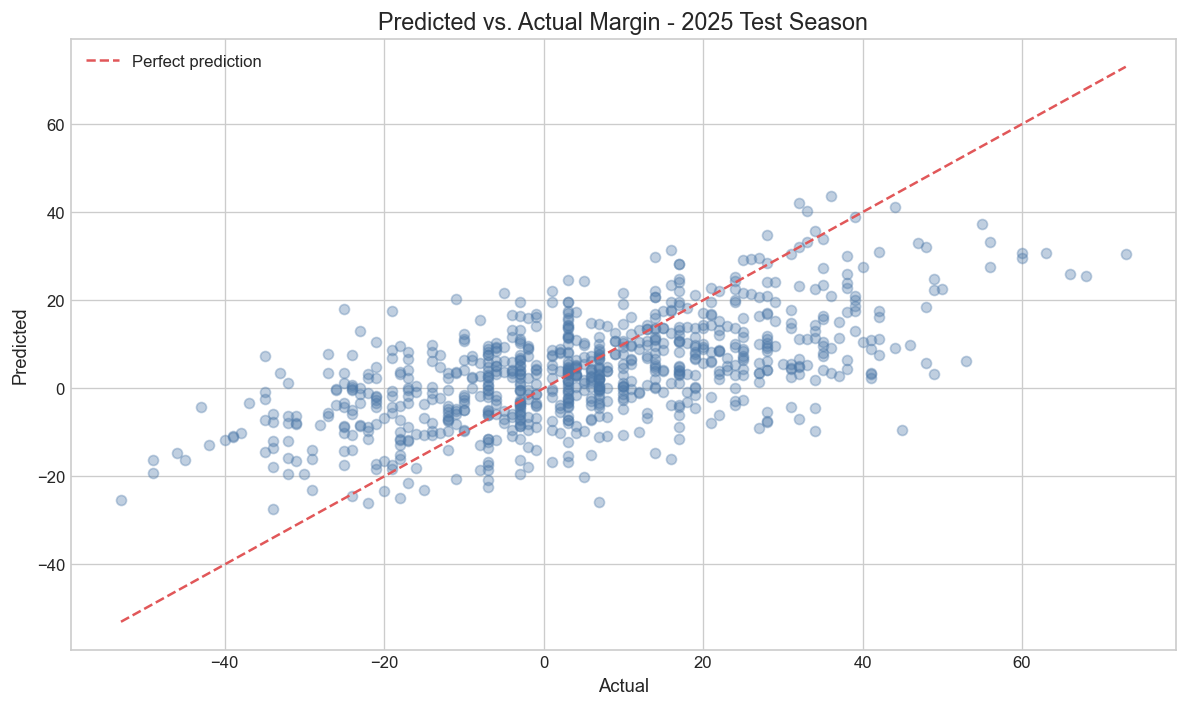

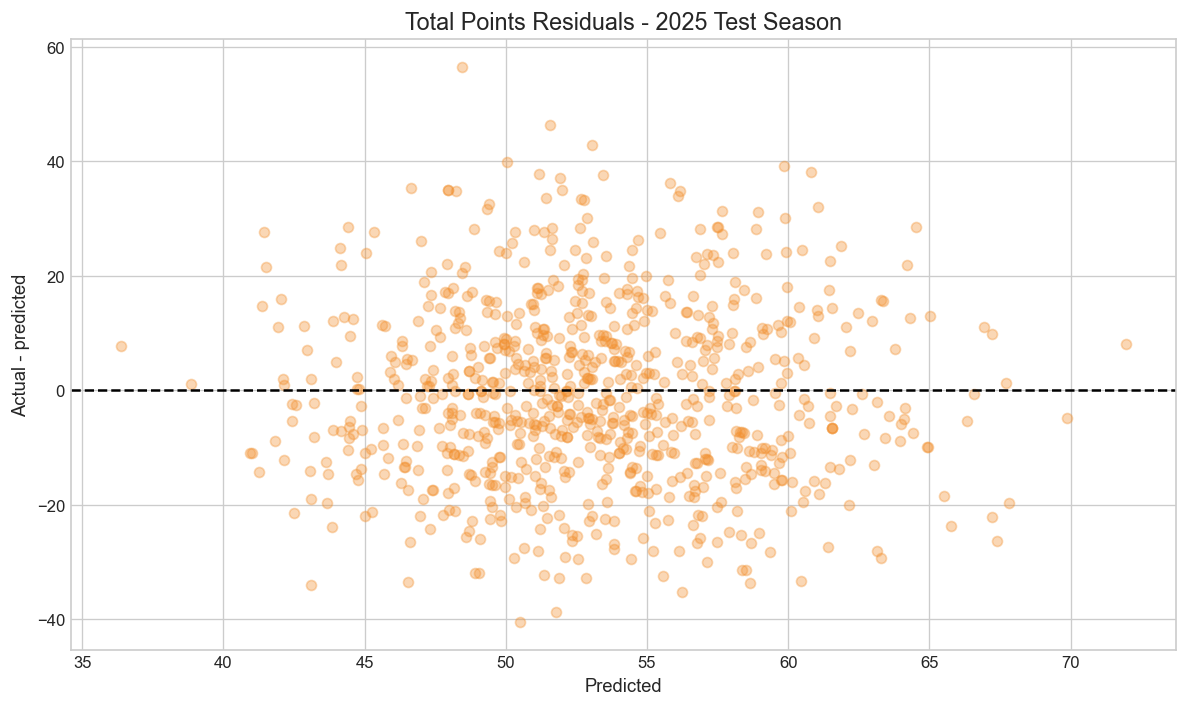

In [7]:
predicted_vs_actual(
    test_predictions,
    actual='actual_margin',
    predicted='model_margin',
    title='Predicted vs. Actual Margin - 2025 Test Season',
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'test_margin_predictions.png', bbox_inches='tight')
plt.show()

residual_plot(
    test_predictions,
    actual='actual_total',
    predicted='model_total',
    title='Total Points Residuals - 2025 Test Season',
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'test_total_residuals.png', bbox_inches='tight')
plt.show()

## Neural Network Training History

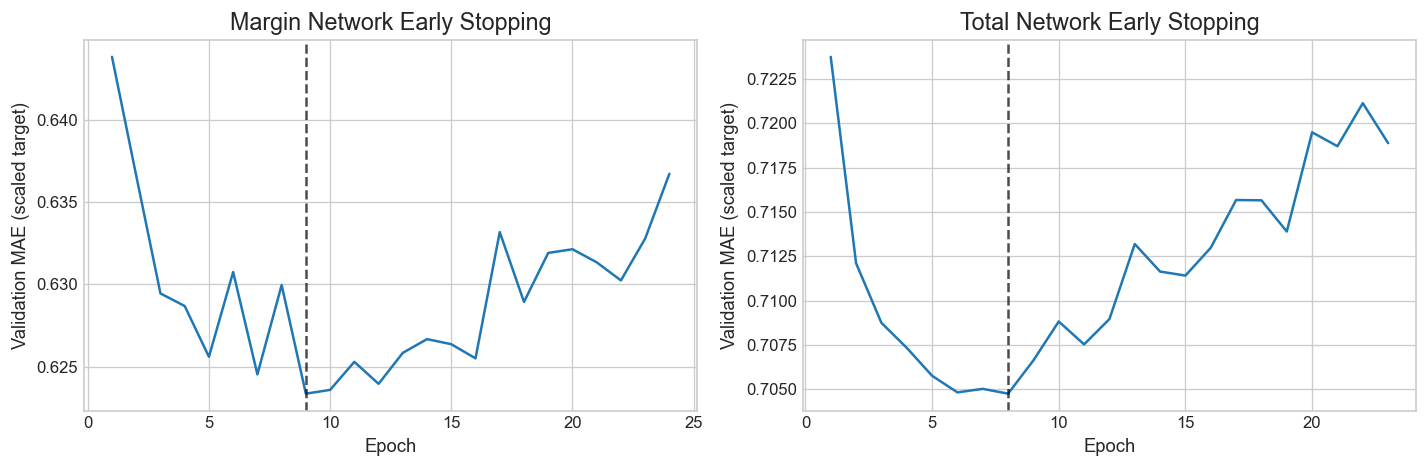

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, target in zip(axes, ['margin', 'total']):
    network = model_bundle[f'{target}_models']['Neural Network'].named_steps['model']
    history = pd.DataFrame(network.early_stopping_history_)
    axis.plot(history['epoch'], history['validation_mae_scaled'])
    axis.axvline(network.best_epoch_, color='black', linestyle='--', alpha=0.7)
    axis.set(
        title=f'{target.title()} Network Early Stopping',
        xlabel='Epoch',
        ylabel='Validation MAE (scaled target)',
    )
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'neural_network_training.png', bbox_inches='tight')
plt.show()

The dashed line marks the epoch retained by early stopping. The selected number of epochs is then used for a final refit on the full training set, so the internal validation records are not discarded.

## Comparison to the Betting Market

In [9]:
market_games = test_predictions.dropna(subset=['market_margin', 'market_total']).copy()
market_games = add_market_score_predictions(market_games)

comparison = pd.concat(
    [
        regression_metrics(market_games, prefix='model').rename('Statistics-only model'),
        regression_metrics(market_games, prefix='market').rename('Market'),
    ],
    axis=1,
)
comparison

,Statistics-only model,Market
games,808.000000,808.000000
margin_mae,12.547185,11.822710
margin_rmse,15.978152,15.007040
total_mae,12.650633,12.539604
total_rmse,15.647264,15.545157
home_score_mae,9.403653,9.048731
away_score_mae,8.508899,8.139697
winner_accuracy,0.728960,0.736386
margin_r2,0.373379,0.447233
total_r2,0.092799,0.104601


In [10]:
margin_comparison = paired_bootstrap_mae_difference(
    market_games,
    actual_column='actual_margin',
    first_prediction='model_margin',
    second_prediction='market_margin',
)
total_comparison = paired_bootstrap_mae_difference(
    market_games,
    actual_column='actual_total',
    first_prediction='model_total',
    second_prediction='market_total',
)

pd.DataFrame([margin_comparison, total_comparison], index=['Margin', 'Total'])

,mean_mae_difference,lower_95,upper_95
Margin,0.724475,0.369811,1.063959
Total,0.111029,-0.116825,0.339168


A negative MAE difference favors the statistics-only model, while a positive difference favors the market. The paired bootstrap resamples games rather than treating the two sets of errors as independent.

## Statistics-Plus-Market Hybrid

In [11]:
hybrid_training = calibration_predictions.dropna(
    subset=['model_margin', 'model_total', 'market_margin', 'market_total']
).copy()

margin_hybrid = LinearRegression().fit(
    hybrid_training[['model_margin', 'market_margin']],
    hybrid_training['actual_margin'],
)
total_hybrid = LinearRegression().fit(
    hybrid_training[['model_total', 'market_total']],
    hybrid_training['actual_total'],
)

market_games['hybrid_margin'] = margin_hybrid.predict(
    market_games[['model_margin', 'market_margin']]
)
market_games['hybrid_total'] = total_hybrid.predict(
    market_games[['model_total', 'market_total']]
)
market_games['hybrid_home_score'] = np.maximum(
    0, (market_games['hybrid_total'] + market_games['hybrid_margin']) / 2
)
market_games['hybrid_away_score'] = np.maximum(
    0, (market_games['hybrid_total'] - market_games['hybrid_margin']) / 2
)

hybrid_metrics = regression_metrics(market_games, prefix='hybrid')
final_comparison = pd.concat([comparison, hybrid_metrics.rename('Hybrid')], axis=1)
final_comparison

,Statistics-only model,Market,Hybrid
games,808.000000,808.000000,808.000000
margin_mae,12.547185,11.822710,11.823923
margin_rmse,15.978152,15.007040,14.988211
total_mae,12.650633,12.539604,12.622952
total_rmse,15.647264,15.545157,15.580347
home_score_mae,9.403653,9.048731,9.154763
away_score_mae,8.508899,8.139697,8.151972
winner_accuracy,0.728960,0.736386,0.736386
margin_r2,0.373379,0.447233,0.448619
total_r2,0.092799,0.104601,0.100542


In [12]:
joblib.dump(
    {'margin_hybrid': margin_hybrid, 'total_hybrid': total_hybrid},
    MODEL_DIR / 'hybrid_models.joblib',
)

test_predictions.to_csv(EVALUATION_DIR / 'test_predictions_2025.csv', index=False)
market_games.to_csv(EVALUATION_DIR / 'market_comparison_2025.csv', index=False)
final_comparison.to_csv(EVALUATION_DIR / 'final_metrics.csv')

## Model Interpretation

In [13]:
if model_bundle['margin_primary'] == 'Stacking Ensemble':
    margin_predictor = StackedTargetPredictor(
        models=model_bundle['margin_models'],
        stacker=model_bundle['margin_stacker'],
        model_names=model_bundle['margin_model_names'],
    )
else:
    margin_predictor = model_bundle['margin_models'][model_bundle['margin_primary']]

# Repeated small predictions are faster without creating a new parallel tree pool each time.
if hasattr(margin_predictor, 'named_steps'):
    selected_estimator = margin_predictor.named_steps.get('model')
    if hasattr(selected_estimator, 'n_jobs'):
        selected_estimator.set_params(n_jobs=1)

importance = permutation_importance(
    margin_predictor,
    test_games[model_bundle['features']],
    test_games['actual_margin'],
    scoring='neg_mean_absolute_error',
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)

importance_df = pd.DataFrame({
    'feature': model_bundle['features'],
    'importance': importance.importances_mean,
}).sort_values('importance', ascending=False)
importance_df.to_csv(EVALUATION_DIR / 'margin_permutation_importance.csv', index=False)
importance_df.head(15)

,feature,importance
102,elo_home_win_probability,0.842502
101,elo_diff,0.614783
157,recruiting_points_diff,0.220139
159,talent_diff,0.162479
81,diff_points_against_season,0.037989
76,diff_offense_success_rate_ewm,0.023354
59,diff_defense_ppa_season,0.017367
62,diff_defense_success_rate_season,0.014846
52,conference_game,0.014436
77,diff_offense_success_rate_last_5,0.010297


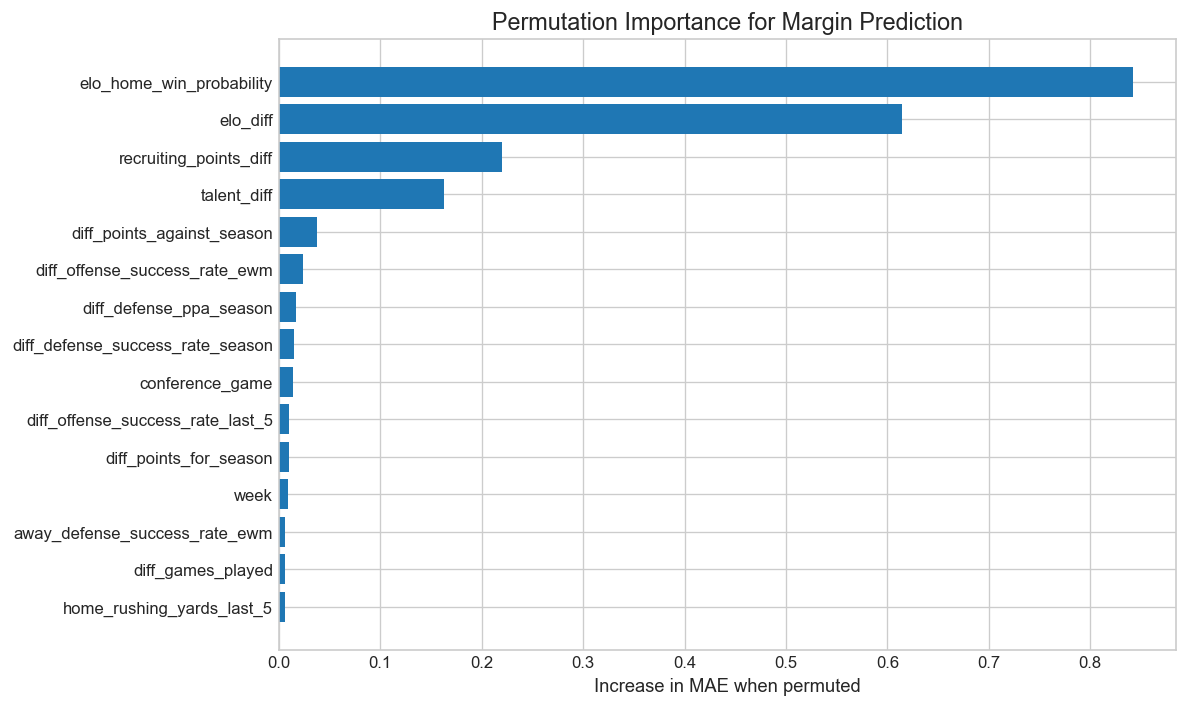

In [14]:
fig, axis = plt.subplots(figsize=(10, 6))
top_features = importance_df.head(15).sort_values('importance')
axis.barh(top_features['feature'], top_features['importance'])
axis.set(title='Permutation Importance for Margin Prediction', xlabel='Increase in MAE when permuted')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'margin_feature_importance.png', bbox_inches='tight')
plt.show()

## Conclusion

The final comparison should be interpreted using the locked primary systems, not the model family that happens to rank first on the test table. The market and hybrid analyses remain separate from the original statistics-only experiment, which makes it clear when betting information enters the project.